# Analisis pengembangan Risiko Fraud pada Transaksi Self-Checkout

# Latar belakang
Project ini mengeksplorasi data transaksi self-checkout untuk memahami pola yang berkaitan dengan transaksi berlabel fraud. Fokus analisis bukan hanya mengejar akurasi, tetapi juga melihat ketidakseimbangan kelas, membandingkan metrik model, dan mengidentifikasi fitur yang berpotensi membantu proses pemeriksaan transaksi.

Di project ini, kita akan:
- Melihat isi dan kualitas data.
- Membandingkan transaksi fraud dan non-fraud.
- Membuat beberapa model machine learning.
- Membandingkan hasil model dengan beberapa ukuran penilaian.
- Melihat fitur yang dianggap penting oleh model.

# 1. Persiapan Library

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
    classification_report
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

# 2. Mengambil data dan melihat isi datanya

In [4]:
! git clone https://github.com/zaza-ipynb/Data-Mining-Cup-2019.git
!unzip -o Data-Mining-Cup-2019/dmc.zip

fatal: destination path 'Data-Mining-Cup-2019' already exists and is not an empty directory.
Archive:  Data-Mining-Cup-2019/dmc.zip
  inflating: DMC_2019_task/DATA-MINING-CUP-2019-features.pdf  
  inflating: DMC_2019_task/DATA-MINING-CUP-2019-task.pdf  
  inflating: DMC_2019_task/test.csv  
  inflating: DMC_2019_task/train.csv  


melakukan import data yang telah di download

In [5]:
 df = pd.read_csv('DMC_2019_task/train.csv', sep='|')
pred = pd.read_csv('DMC_2019_task/test.csv', sep='|')
real = pd.read_csv('Data-Mining-Cup-2019/DMC-2019-realclass.csv', sep='|')

In [6]:
df.shape, pred.shape, real.shape

((1879, 10), (498121, 9), (498121, 1))

over view

In [8]:
pred.head()

,trustLevel,totalScanTimeInSeconds,grandTotal,lineItemVoids,scansWithoutRegistration,quantityModifications,scannedLineItemsPerSecond,valuePerSecond,lineItemVoidsPerPosition
0,4,467,88.48,4,8,4,0.014989,0.189465,0.571429
1,3,1004,58.99,7,6,1,0.026892,0.058755,0.259259
2,1,162,14.00,4,5,4,0.006173,0.086420,4.000000
3,5,532,84.79,9,3,4,0.026316,0.159380,0.642857
4,5,890,42.16,4,0,0,0.021348,0.047371,0.210526


In [10]:
display(df.info())
display(df.describe(include="all").T)
quality_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique()
})
display(quality_summary)
print("Jumlah baris duplikat:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1879 entries, 0 to 1878
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   trustLevel                 1879 non-null   int64  
 1   totalScanTimeInSeconds     1879 non-null   int64  
 2   grandTotal                 1879 non-null   float64
 3   lineItemVoids              1879 non-null   int64  
 4   scansWithoutRegistration   1879 non-null   int64  
 5   quantityModifications      1879 non-null   int64  
 6   scannedLineItemsPerSecond  1879 non-null   float64
 7   valuePerSecond             1879 non-null   float64
 8   lineItemVoidsPerPosition   1879 non-null   float64
 9   fraud                      1879 non-null   int64  
dtypes: float64(4), int64(6)
memory usage: 146.9 KB


None

,count,mean,std,min,25%,50%,75%,max
trustLevel,1879.0,3.401809,1.709404,1.000000,2.000000,3.000000,5.000000,6.000000
totalScanTimeInSeconds,1879.0,932.153273,530.144640,2.000000,474.500000,932.000000,1397.000000,1831.000000
grandTotal,1879.0,50.864492,28.940202,0.010000,25.965000,51.210000,77.285000,99.960000
lineItemVoids,1879.0,5.469931,3.451169,0.000000,2.000000,5.000000,8.000000,11.000000
scansWithoutRegistration,1879.0,4.904204,3.139697,0.000000,2.000000,5.000000,8.000000,10.000000
quantityModifications,1879.0,2.525279,1.695472,0.000000,1.000000,3.000000,4.000000,5.000000
scannedLineItemsPerSecond,1879.0,0.058138,0.278512,0.000548,0.008384,0.016317,0.032594,6.666667
valuePerSecond,1879.0,0.201746,1.242135,0.000007,0.027787,0.054498,0.107313,37.870000
lineItemVoidsPerPosition,1879.0,0.745404,1.327241,0.000000,0.160000,0.350000,0.666667,11.000000
fraud,1879.0,0.055349,0.228720,0.000000,0.000000,0.000000,0.000000,1.000000


,missing_values,missing_percent,n_unique
trustLevel,0,0.0,6
totalScanTimeInSeconds,0,0.0,1193
grandTotal,0,0.0,1721
lineItemVoids,0,0.0,12
scansWithoutRegistration,0,0.0,11
quantityModifications,0,0.0,6
scannedLineItemsPerSecond,0,0.0,1772
valuePerSecond,0,0.0,1879
lineItemVoidsPerPosition,0,0.0,216
fraud,0,0.0,2


Jumlah baris duplikat: 0


dari konteks di atas data di nyatakan sudah benar2 clear

# 3. Dsitribusi label dan dampak class imbalance


In [12]:
# melakukan perhitungan jumlah dan persentasi transaksi dari fraud dan non fraud
class_count = df["fraud"].value_counts().sort_index()
class_percent = (df["fraud"].value_counts(normalize=True).sort_index() * 100).round(2)
class_summary = pd.DataFrame({
    "jumlah_transaksi": class_count,
    "persentase": class_percent
})
class_summary.index = ["Non-fraud (0)" if i == 0 else "Fraud (1)" for i in class_summary.index]
display(class_summary)

,jumlah_transaksi,persentase
Non-fraud (0),1775,94.47
Fraud (1),104,5.53


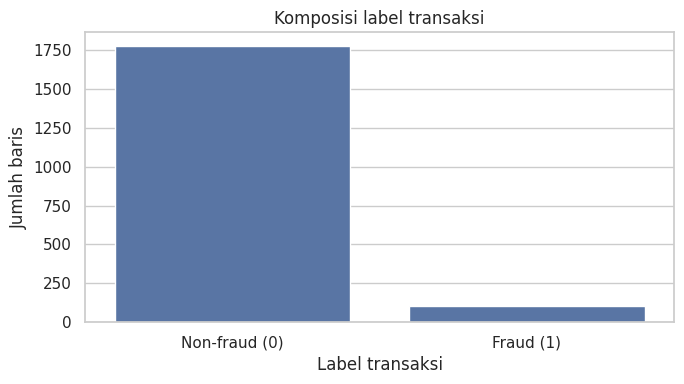

In [13]:
#menampilkan grafiknya
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=class_summary.index, y=class_summary["jumlah_transaksi"])
ax.set_title("Komposisi label transaksi")
ax.set_xlabel("Label transaksi")
ax.set_ylabel("Jumlah baris")
plt.tight_layout()
plt.show()

jumlah transaksi fraud lebih sedikit jika di bandingkan transaksi normal, perbedaan tsb ngebuat data tidak seimbang, oelh karena itu penilaian model tidak cukup hanya menggunakan akurasi karna bisa menyesatkan. untuk mengetahui kemampuan model lebih baik, analisis ini juga harus menggunakan precision, recall, dan f1-score

# 4. membandingkan ciri dari transaksi

In [15]:
# membandingkan median fitur pada transaksi fraud dan non-fraud

numeric_features = df.select_dtypes(include=np.number).columns.drop("fraud", errors="ignore")
comparison = df.groupby("fraud")[list(numeric_features)].median().T
comparison.columns = ["Non-fraud (0)", "Fraud (1)"]
comparison["selisih_median"] = comparison["Fraud (1)"] - comparison["Non-fraud (0)"]
display(comparison.sort_values("selisih_median", key=lambda s: s.abs(), ascending=False))


,Non-fraud (0),Fraud (1),selisih_median
totalScanTimeInSeconds,916.000000,1309.500000,393.500000
grandTotal,51.260000,48.670000,-2.590000
trustLevel,3.000000,1.000000,-2.000000
scansWithoutRegistration,5.000000,7.000000,2.000000
lineItemVoids,5.000000,6.000000,1.000000
quantityModifications,3.000000,2.000000,-1.000000
lineItemVoidsPerPosition,0.363636,0.245000,-0.118636
valuePerSecond,0.055407,0.043697,-0.011710
scannedLineItemsPerSecond,0.015873,0.020436,0.004563


membandingkan nilai tengah (median) setiap fitur pada transaksi fraud dan non-fraud. Median membantu melihat perbedaan umum tanpa terlalu dipengaruhi oleh nilai yang sangat besar atau sangat kecil.

# 6. melihat hubungan antarfitur

In [18]:
# menampilkan korelasi setiap fitur dengan label fraud.
display(corr["fraud"].drop("fraud").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_fraud"))

,correlation_with_fraud
trustLevel,-0.319765
totalScanTimeInSeconds,0.110414
lineItemVoidsPerPosition,-0.090116
scansWithoutRegistration,0.074123
lineItemVoids,0.063496
valuePerSecond,-0.028873
scannedLineItemsPerSecond,-0.023085
grandTotal,0.001421
quantityModifications,-0.000864


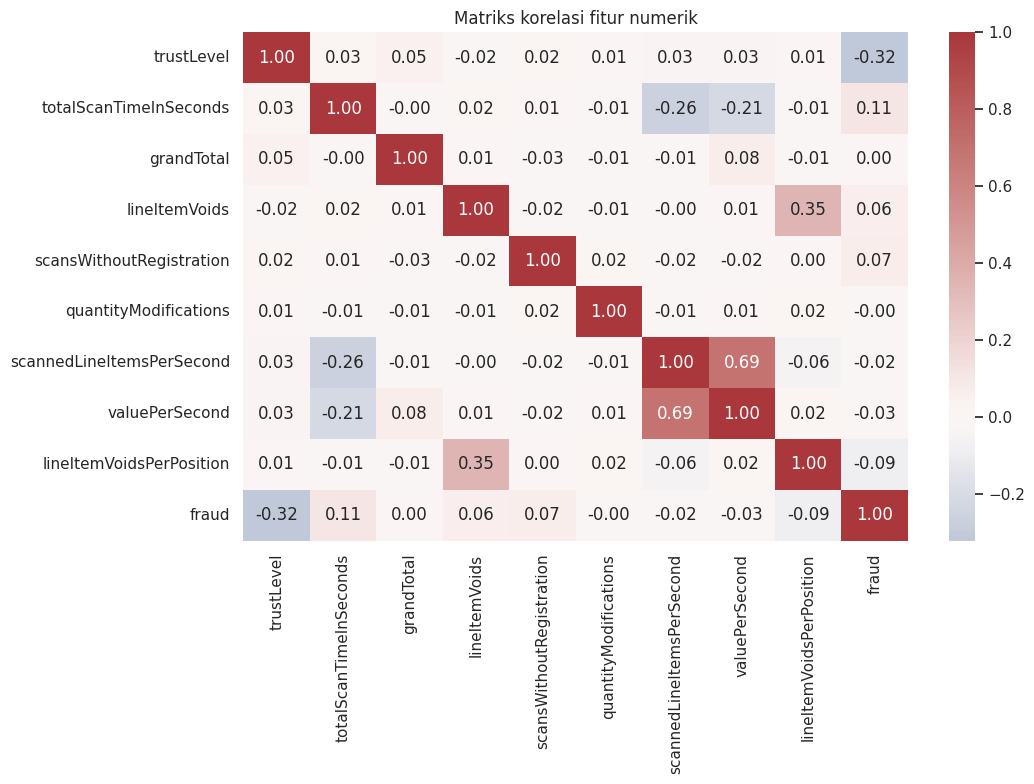

In [19]:
# membuat heatmap korelasi

corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f")
plt.title("Matriks korelasi fitur numerik")
plt.tight_layout()
plt.show()


Korelasi menunjukkan seberapa kuat dua nilai numerik bergerak bersama secara linear. positif berarti keduanya cenderung naik bersama, sedangkan negatif berarti salah satunya cenderung turun saat yang lain naik.
Korelasi hanya pemeriksaan awal. Korelasi yang kecil tidak selalu berarti sebuah fitur tidak berguna, dan korelasi tidak membuktikan hubungan sebab-akibat.

#7. membagi data untuk membuat dan menguji model

In [20]:
# memisahkan kolom fitur (X) dan label (y), lalu membagi data menjadi training dan validation.

X = df.drop(columns="fraud")
y = df["fraud"].astype(int)

# fitur numerik untuk baseline yang konsisten.
X = X.select_dtypes(include=np.number)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training:", X_train.shape, "| Validation:", X_valid.shape)
print("Proporsi fraud training:", round(y_train.mean() * 100, 2), "%")
print("Proporsi fraud validation:", round(y_valid.mean() * 100, 2), "%")

Training: (1409, 9) | Validation: (470, 9)
Proporsi fraud training: 5.54 %
Proporsi fraud validation: 5.53 %


data berlabel dibagi menjadi dua bagian:
- training: digunakan model untuk belajar dari data.
- validation: digunakan untuk memeriksa kemampuan model pada data yang tidak dipakai saat belajar.

stratify=y membantu menjaga perbandingan label fraud dan non-fraud agar kurang lebih sama pada kedua bagian. langkah pengisian nilai kosong dan standardisasi dilakukan di dalam pipeline model supaya dipelajari dari data training.

# 8. membandingkan beberapa model

mencoba tiga model:
- dummy Classifier: model sederhana sebagai pembanding awal.
- logistic Regression: model yang mempelajari hubungan secara lebih sederhana dan cenderung linear.
- random Forest: gabungan banyak pohon keputusan yang dapat mempelajari pola yang lebih kompleks.

hasilnya dibandingkan menggunakan beberapa metrik. average precision dipakai untuk membantu menilai kemampuan model menemukan kelas fraud, terutama jika jumlah label tidak seimbang.

In [22]:
# menyiapkan tiga model dan melatihnya

models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

In [23]:
# kemudian membandingkan hasilnya dengan beberapa metrik evaluasi.
results = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred_label = model.predict(X_valid)
    if hasattr(model, "predict_proba"):
        pred_score = model.predict_proba(X_valid)[:, 1]
    else:
        pred_score = pred_label
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_valid, pred_label),
        "precision_fraud": precision_score(y_valid, pred_label, zero_division=0),
        "recall_fraud": recall_score(y_valid, pred_label, zero_division=0),
        "f1_fraud": f1_score(y_valid, pred_label, zero_division=0),
        "roc_auc": roc_auc_score(y_valid, pred_score) if len(np.unique(y_valid)) == 2 else np.nan,
        "average_precision": average_precision_score(y_valid, pred_score)
    })

results_df = pd.DataFrame(results).set_index("model").sort_values("average_precision", ascending=False)
display(results_df.round(3))

,accuracy,precision_fraud,recall_fraud,f1_fraud,roc_auc,average_precision
model,,,,,,
Random Forest,0.974,0.769,0.769,0.769,0.993,0.889
Logistic Regression,0.891,0.338,1.000,0.505,0.979,0.712
Dummy (most frequent),0.945,0.000,0.000,0.000,0.500,0.055


# 9. Melihat hasil model terbaik
memilih model dengan nilai average precision tertinggi pada data validation. bagian ini menampilkan laporan penilaian dan confusion matrix.

- precision fraud: dari transaksi yang diprediksi fraud, berapa banyak yang benar-benar berlabel fraud.
- recall fraud: dari semua transaksi yang berlabel fraud, berapa banyak yang berhasil ditemukan model.
- f1-score: gabungan precision dan recall.
- confusion matrix: menunjukkan jumlah prediksi yang benar dan salah untuk tiap label.

model terbaik di sini berarti terbaik menurut metrik dan pembagian data yang digunakan

Model dengan average precision tertinggi pada split ini: Random Forest
              precision    recall  f1-score   support

   Non-fraud       0.99      0.99      0.99       444
       Fraud       0.77      0.77      0.77        26

    accuracy                           0.97       470
   macro avg       0.88      0.88      0.88       470
weighted avg       0.97      0.97      0.97       470



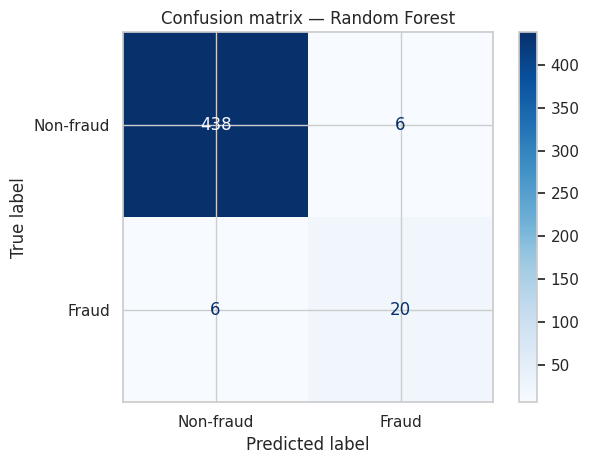

In [24]:
# mengambil model dengan average precision tertinggi, menampilkan laporan evaluasi, dan membuat confusion matrix.

best_model_name = results_df.index[0]
best_model = fitted_models[best_model_name]
valid_pred = best_model.predict(X_valid)
valid_score = best_model.predict_proba(X_valid)[:, 1] if hasattr(best_model, "predict_proba") else valid_pred

print("Model dengan average precision tertinggi pada split ini:", best_model_name)
print(classification_report(y_valid, valid_pred, target_names=["Non-fraud", "Fraud"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_pred, display_labels=["Non-fraud", "Fraud"], cmap="Blues"
)
plt.title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

# 10. Melihat fitur yang dianggap penting


,feature_importance
trustLevel,0.487274
scannedLineItemsPerSecond,0.176726
lineItemVoidsPerPosition,0.111800
totalScanTimeInSeconds,0.081932
valuePerSecond,0.050655
grandTotal,0.030294
lineItemVoids,0.026621
scansWithoutRegistration,0.025434
quantityModifications,0.009263


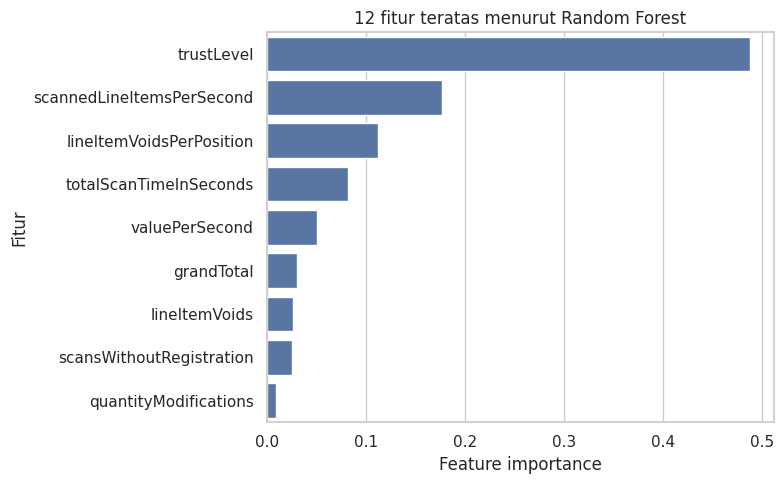

In [25]:
# menampilkan fitur yang dianggap penting oleh Random Forest, jika model tersebut tersedia.

rf_pipeline = fitted_models.get("Random Forest")
if rf_pipeline is not None:
    rf = rf_pipeline.named_steps["model"]
    importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    display(importance.head(12).to_frame("feature_importance"))
    plt.figure(figsize=(8, 5))
    sns.barplot(x=importance.head(12).values, y=importance.head(12).index)
    plt.title("12 fitur teratas menurut Random Forest")
    plt.xlabel("Feature importance")
    plt.ylabel("Fitur")
    plt.tight_layout()
    plt.show()

menampilkan fitur yang paling banyak membantu model membuat pemisahan data.

feature importance membantu kita memahami model, tetapi tidak membuktikan bahwa fitur tersebut menyebabkan fraud. Hasilnya juga bisa dipengaruhi oleh bentuk dan kualitas data.

# 11. hasil akhir

* Insight 1 — Jumlah transaksi fraud relatif sedikit
5,53%
Dari 1.879 transaksi pada data training, terdapat 104 transaksi fraud dan 1.775 transaksi non-fraud. Artinya, data tidak seimbang karena transaksi fraud jauh lebih sedikit.

* Insight 2 — Trust level berkaitan dengan indikasi fraud
−0,320
Nilai korelasi trustLevel dengan fraud sekitar −0,320. Ini menunjukkan hubungan negatif dalam data tersebut: nilai trust level yang lebih tinggi cenderung berkaitan dengan label fraud yang lebih rendah. Namun, korelasi tidak membuktikan sebab-akibat.

* Insight 3 — Penyeimbangan data memengaruhi evaluasi model
Teknik downsampling mengurangi jumlah data non-fraud, sedangkan oversampling menambah sampel fraud melalui pengambilan ulang data fraud yang tersedia. Perbedaan teknik ini menghasilkan nilai evaluasi yang berbeda.

Perbandingan model:
* Data tidak seimbang: model memperoleh accuracy 98,67%, tetapi angka ini belum cukup untuk memastikan model mampu menemukan transaksi fraud dengan baik.

* Downsampling: accuracy dan ROC-AUC lebih rendah dibandingkan model pada data tidak seimbang. Namun, hasil ini belum membuktikan bahwa downsampling selalu lebih buruk.

* Oversampling: menghasilkan nilai evaluasi tertinggi pada pengujian yang tercatat. Akan tetapi, nilai ROC-AUC 1,0000 perlu diperiksa lebih lanjut sebelum menyimpulkan bahwa model sangat sempurna.

Kesimpulan

Berdasarkan hasil analisis, transaksi fraud pada sistem self-checkout memiliki jumlah yang jauh lebih sedikit dibandingkan transaksi non-fraud. Dari 1.879 transaksi pada data training, hanya 104 transaksi atau sekitar 5,53% yang termasuk fraud. Kondisi ini menunjukkan bahwa ketidakseimbangan kelas menjadi salah satu tantangan utama dalam membangun model deteksi fraud.

Hasil analisis korelasi menunjukkan bahwa fitur `trustLevel` memiliki hubungan negatif dengan label fraud, dengan nilai korelasi sekitar -0,320. Temuan ini menunjukkan bahwa tingkat kepercayaan pelanggan dapat menjadi salah satu informasi yang berguna dalam proses deteksi, tetapi tidak cukup untuk menentukan fraud secara mandiri.

Pengujian menggunakan Random Forest menghasilkan accuracy sebesar 98,67% pada data tidak seimbang, 97,62% setelah downsampling, dan 99,30% setelah oversampling. Meskipun oversampling menghasilkan nilai tertinggi, hasil tersebut perlu diuji kembali menggunakan pemisahan data yang benar untuk menghindari kebocoran data.

Secara keseluruhan, model deteksi fraud perlu dievaluasi tidak hanya berdasarkan accuracy, tetapi juga berdasarkan precision, recall, F1-score, dan ROC-AUC. Dengan evaluasi yang tepat, model diharapkan dapat membantu mengidentifikasi transaksi yang perlu diperiksa lebih lanjut tanpa terlalu banyak menandai transaksi normal sebagai fraud.